<a href="https://colab.research.google.com/github/SaloniSrivastava07/Loan-Eligibility-Prediction-Project/blob/main/Breast_Cancer_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BREAST CANCER DIAGNOSIS PROJECT

Code transcribed from the uploaded 22-page Colab PDF. Where the PDF cuts off a line, the code is reconstructed only enough to make the visible workflow usable; this is not the original recovered `.ipynb`.

## IMPORT REQUIRED LIBRARIES

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier


## LOADING AND INSPECTING DATA

In [4]:
data = pd.read_csv("/content/Breast_cancer_dataset.csv")

# TO DISPLAY FIRST 5 ROWS OF THE DATA
data.head()


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
# TO DISPLAY BASIC INFORMATION OF THE DATASET
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [6]:
# TO CHECK THE CLASS DISTRIBUTION (Benign and Malignant)
data['diagnosis'].value_counts()


,count
diagnosis,
B,357
M,212


## EDA

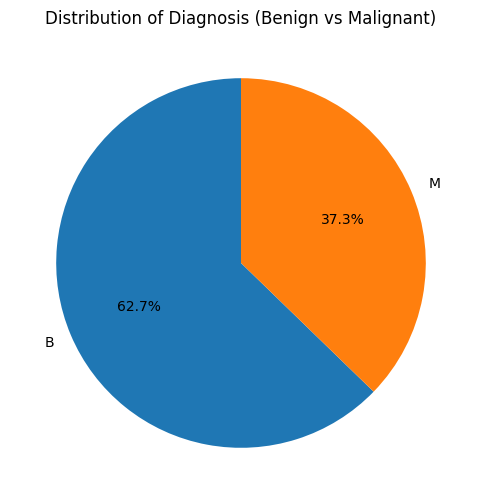

In [7]:
# Class Distribution (B vs M)
plt.figure(figsize=(6, 6))
data['diagnosis'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title("Distribution of Diagnosis (Benign vs Malignant)")
plt.ylabel("")  # hides y-axis
plt.show()


In [8]:
# SUMMARY STATISTICS
data.describe().T


,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


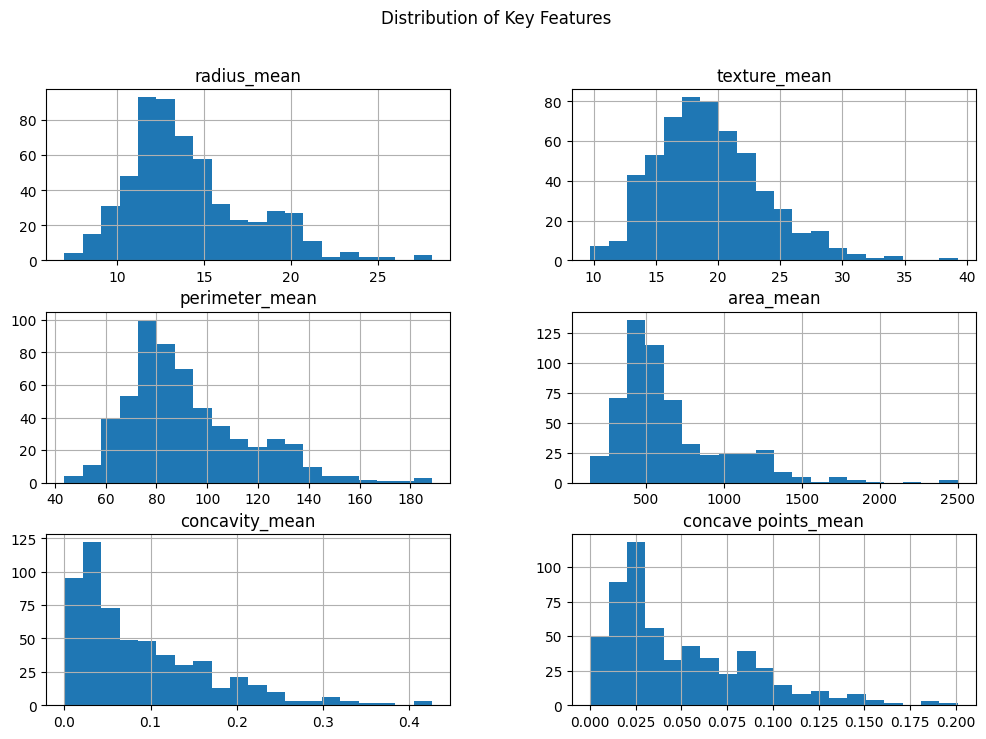

In [9]:
from seaborn.distributions import kdeplot

# HISTOGRAM OF FEATURES
important_features = [
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
    'concavity_mean', 'concave points_mean'
]

data[important_features].hist(bins=20, figsize=(12, 8))
plt.suptitle("Distribution of Key Features")
plt.show()


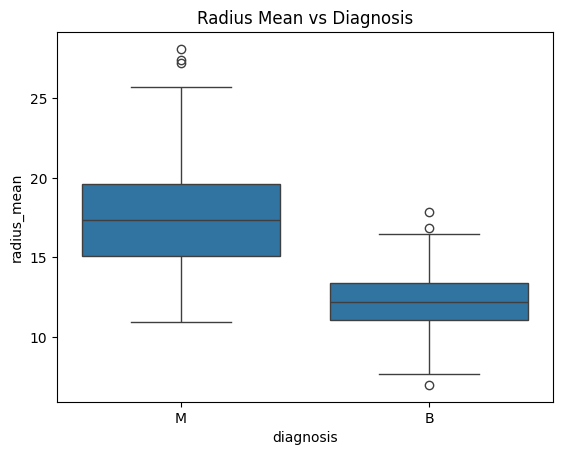

In [10]:
# BOXPLOTS
sns.boxplot(x=data['diagnosis'], y=data['radius_mean'])
plt.title("Radius Mean vs Diagnosis")
plt.show()


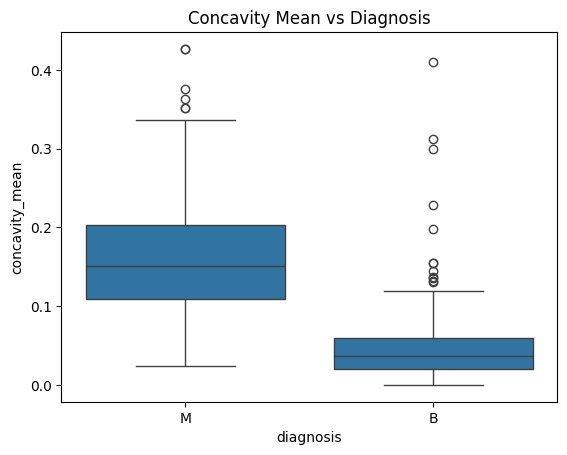

In [11]:
sns.boxplot(x=data['diagnosis'], y=data['concavity_mean'])
plt.title("Concavity Mean vs Diagnosis")
plt.show()


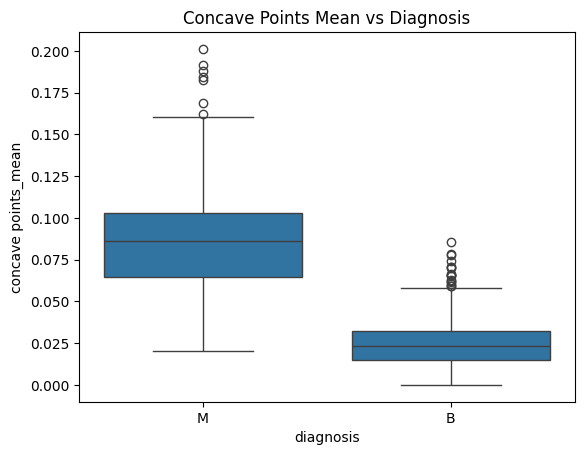

In [12]:
sns.boxplot(x=data['diagnosis'], y=data['concave points_mean'])
plt.title("Concave Points Mean vs Diagnosis")
plt.show()


## DATA PREPROCESSING

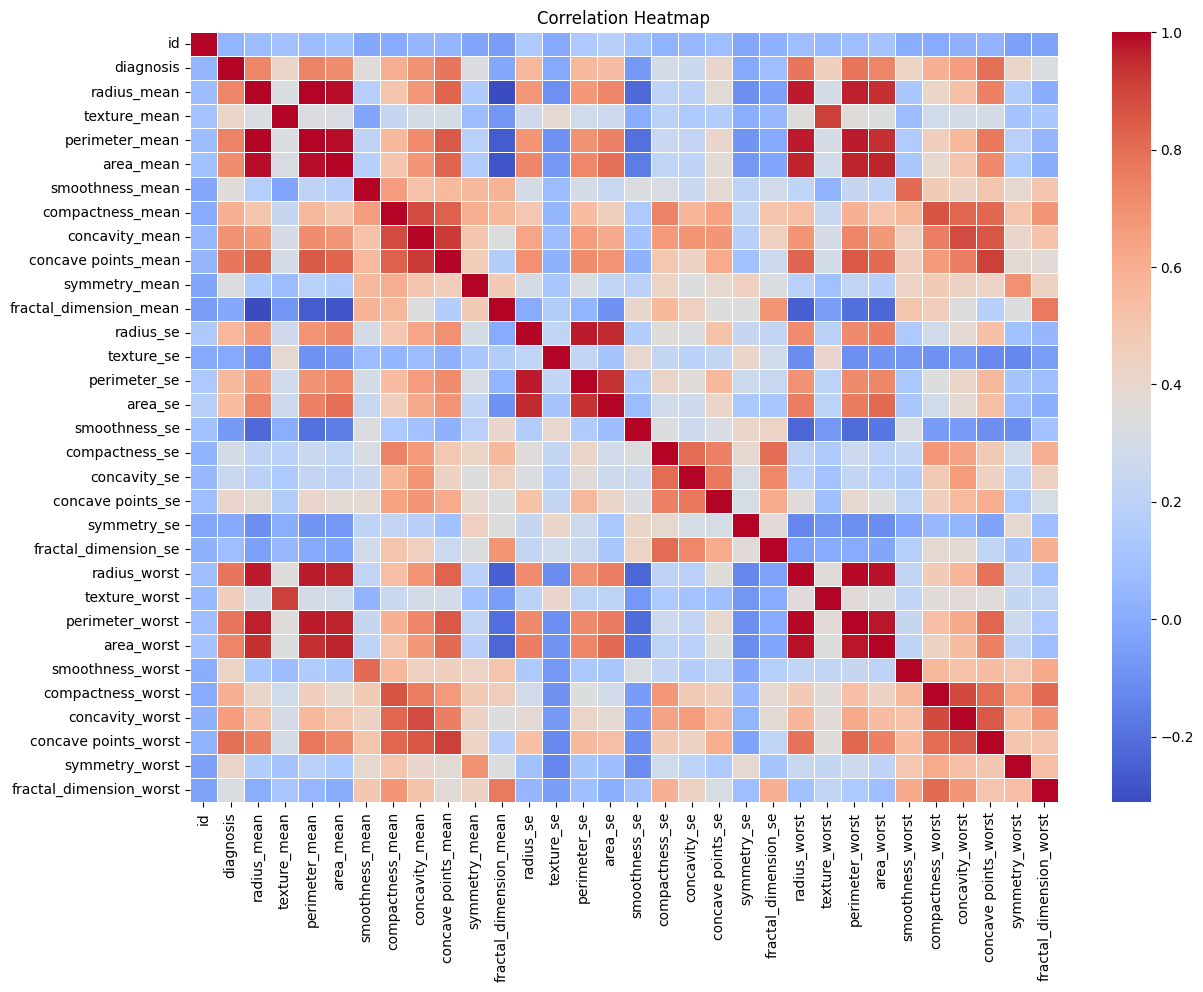

In [13]:
# TO CONVERT THE LABELS (Malignant M = 1 and Benign B = 0)
data['diagnosis'] = data['diagnosis'].map({"M": 1, "B": 0})

# CORRELATION HEATMAP
plt.figure(figsize=(14, 10))
sns.heatmap(data.corr(), cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()


In [14]:
# DROP THE IRRELEVANT COLUMN (ID)
data = data.drop(columns=['id'], errors='ignore')

# TO SPLIT THE DATASET INTO FEATURES & LABELS
X = data.drop('diagnosis', axis=1)
Y = data['diagnosis']

# TO SPLIT THE DATASET INTO TRAINING AND TESTING
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

# TO SCALE FEATURES
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## TRAINING MODELS

In [32]:
# SVM
svm_model = SVC(kernel='rbf', probability=True)
svm_model.fit(X_train_scaled, Y_train)


SVC(probability=True)

In [33]:
# RANDOM FOREST
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, Y_train)


RandomForestClassifier(n_estimators=200, random_state=42)

In [34]:
# GRADIENT BOOSTING
gd_model = GradientBoostingClassifier(random_state=42)
gd_model.fit(X_train, Y_train)


GradientBoostingClassifier(random_state=42)

## EVALUATION MODEL

In [35]:
def evaluate(model, X_test, Y_test):
    Y_pred = model.predict(X_test)

    print("\nAccuracy:", accuracy_score(Y_test, Y_pred))
    print("\nClassification Report:\n", classification_report(Y_test, Y_pred))

    # CONFUSION MATRIX
    cm = confusion_matrix(Y_test, Y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title("Confusion Matrix")
    plt.show()



----------- SVM -----------

Accuracy: 0.9824561403508771

Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99        71
           1       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



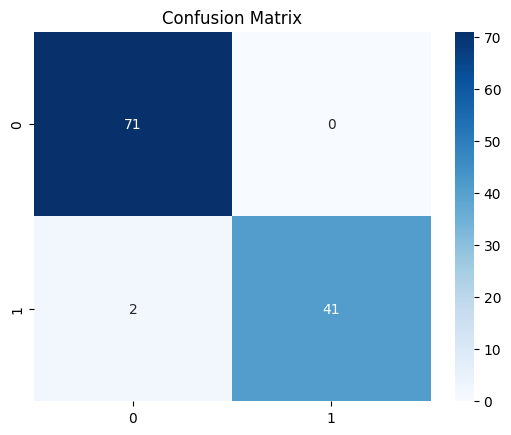


----------- Random Forest -----------

Accuracy: 0.9649122807017544

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.99      0.97        71
           1       0.98      0.93      0.95        43

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



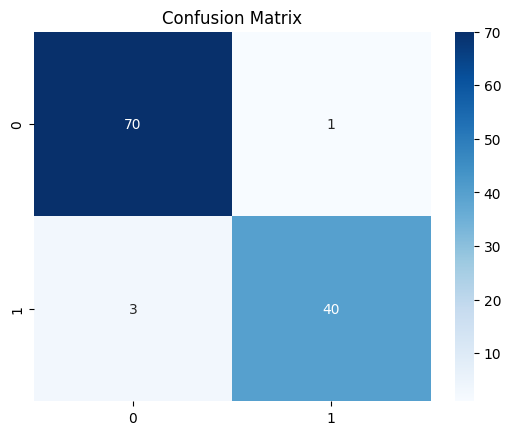


----------- Gradient Boosting -----------

Accuracy: 0.956140350877193

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.97      0.97        71
           1       0.95      0.93      0.94        43

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



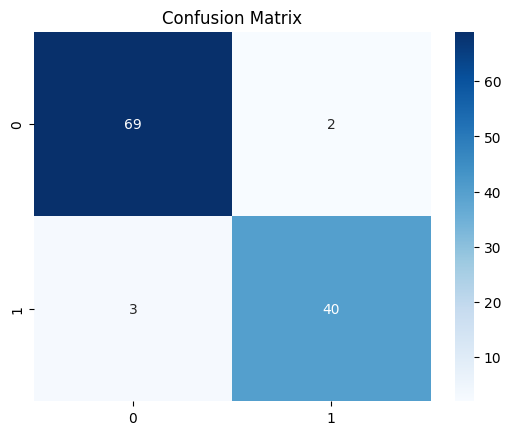

In [36]:
# EVALUATIONS
print("\n----------- SVM -----------")
evaluate(svm_model, X_test_scaled, Y_test)

print("\n----------- Random Forest -----------")
evaluate(rf_model, X_test, Y_test)

print("\n----------- Gradient Boosting -----------")
evaluate(gd_model, X_test, Y_test)


## ROC CURVE COMPARISON

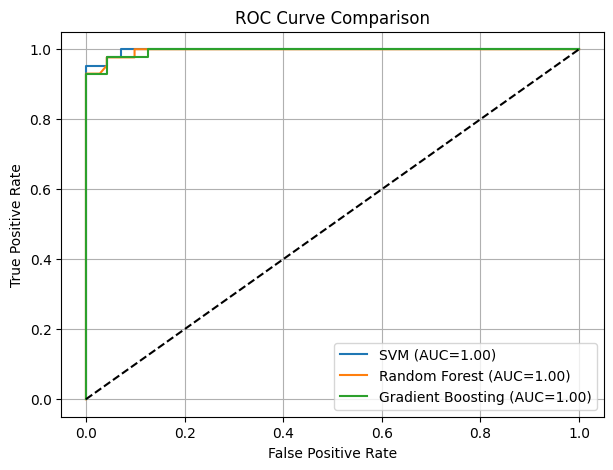

In [37]:
from sklearn.metrics import roc_curve, auc
plt.figure(figsize=(7, 5))

# SVM
svm_probs = svm_model.decision_function(X_test_scaled)
fpr_svm, tpr_svm, _ = roc_curve(Y_test, svm_probs)
auc_svm = auc(fpr_svm, tpr_svm)

# Random Forest
rf_probs = rf_model.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(Y_test, rf_probs)
auc_rf = auc(fpr_rf, tpr_rf)

# Gradient Boosting
gd_probs = gd_model.predict_proba(X_test)[:, 1]
fpr_gd, tpr_gd, _ = roc_curve(Y_test, gd_probs)
auc_gd = auc(fpr_gd, tpr_gd)

plt.plot(fpr_svm, tpr_svm, label=f"SVM (AUC={auc_svm:.2f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC={auc_rf:.2f})")
plt.plot(fpr_gd, tpr_gd, label=f"Gradient Boosting (AUC={auc_gd:.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()


## PRECISION-RECALL CURVE COMPARISON

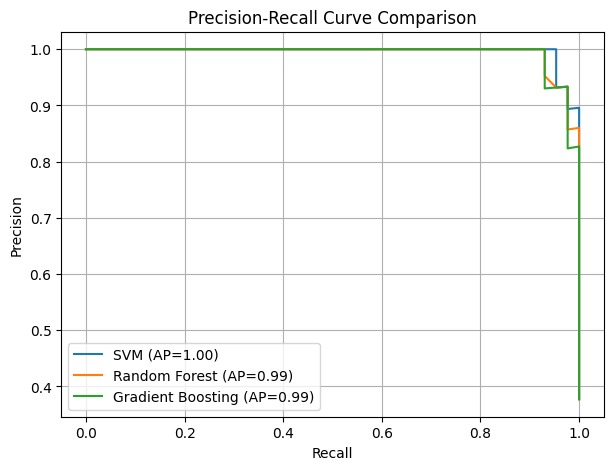

In [38]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(7, 5))

# SVM
precision_svm, recall_svm, _ = precision_recall_curve(Y_test, svm_probs)
ap_svm = average_precision_score(Y_test, svm_probs)

# Random Forest
precision_rf, recall_rf, _ = precision_recall_curve(Y_test, rf_probs)
ap_rf = average_precision_score(Y_test, rf_probs)

# Gradient Boost
precision_gd, recall_gd, _ = precision_recall_curve(Y_test, gd_probs)
ap_gd = average_precision_score(Y_test, gd_probs)

plt.plot(recall_svm, precision_svm, label=f"SVM (AP={ap_svm:.2f})")
plt.plot(recall_rf, precision_rf, label=f"Random Forest (AP={ap_rf:.2f})")
plt.plot(recall_gd, precision_gd, label=f"Gradient Boosting (AP={ap_gd:.2f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()


## METRICS SUMMARY TABLE

In [39]:
results = {
    'Model': ["SVM", "Random Forest", "Gradient Boosting"],
    "Accuracy": [
        accuracy_score(Y_test, svm_model.predict(X_test_scaled)),
        accuracy_score(Y_test, rf_model.predict(X_test)),
        accuracy_score(Y_test, gd_model.predict(X_test))
    ],
    "Precision (Malignant)": [
        classification_report(Y_test, svm_model.predict(X_test_scaled), output_dict=True)['1']['precision'],
        classification_report(Y_test, rf_model.predict(X_test), output_dict=True)['1']['precision'],
        classification_report(Y_test, gd_model.predict(X_test), output_dict=True)['1']['precision']
    ],
    "Recall (Malignant)": [
        classification_report(Y_test, svm_model.predict(X_test_scaled), output_dict=True)['1']['recall'],
        classification_report(Y_test, rf_model.predict(X_test), output_dict=True)['1']['recall'],
        classification_report(Y_test, gd_model.predict(X_test), output_dict=True)['1']['recall']
    ]
}

df_results = pd.DataFrame(results)
df_results


,Model,Accuracy,Precision (Malignant),Recall (Malignant)
0,SVM,0.982456,1.000000,0.953488
1,Random Forest,0.964912,0.975610,0.930233
2,Gradient Boosting,0.956140,0.952381,0.930233


In [40]:
models = {
    'Support Vector Machine': svm_model,
    'Random Forest': rf_model,
    'Gradient Boosting': gd_model
}

# Cross Validation
for name, model in models.items():
    cv_scores = cross_val_score(model, X, Y, cv=5, scoring="accuracy")
    print(f"{name}:")
    print(f"Cross-Validation Scores: {cv_scores}")
    print(f"Mean Accuracy: {np.mean(cv_scores):.2f}")
    print(f"Standard Deviation: {np.std(cv_scores):.2f}")
    print("-" * 50)


Support Vector Machine:
Cross-Validation Scores: [0.85087719 0.89473684 0.92982456 0.94736842 0.9380531 ]
Mean Accuracy: 0.91
Standard Deviation: 0.04
--------------------------------------------------
Random Forest:
Cross-Validation Scores: [0.92105263 0.93859649 0.98245614 0.95614035 0.97345133]
Mean Accuracy: 0.95
Standard Deviation: 0.02
--------------------------------------------------
Gradient Boosting:
Cross-Validation Scores: [0.92105263 0.94736842 0.97368421 0.98245614 0.98230088]
Mean Accuracy: 0.96
Standard Deviation: 0.02
--------------------------------------------------


## SHAP/LIME

### LIME — IMPORT LIME

In [41]:
!pip install lime
from lime import lime_tabular
import numpy as np


In [42]:
from IPython.core.display import HTML  # FOR CLEAR DISPLAY OF RESULT


### INITIALIZE LIME EXPLAINER

In [43]:
lime_explainer = lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X.columns,
    class_names=['Benign', 'Malignant'],
    mode='classification'
)

# EXPLAINING A SINGLE PREDICTION
i = 1


### LIME ON SVM

In [44]:
exp_svm = lime_explainer.explain_instance(
    X_test.iloc[i],
    svm_model.predict_proba
)

html = exp_svm.as_html()
HTML(f"<div style='background:white; padding:10px'>{html}</div>")


/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

### LIME ON RANDOM FOREST

In [45]:
exp_rf = lime_explainer.explain_instance(
    X_test.iloc[i],
    rf_model.predict_proba
)

# exp_rf.show_in_notebook()
html = exp_rf.as_html()
HTML(f"<div style='background:white; padding:10px'>{html}</div>")


/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

### LIME ON GRADIENT BOOSTING

In [46]:
exp_gd = lime_explainer.explain_instance(
    X_test.iloc[i],
    gd_model.predict_proba
)

# exp_gd.show_in_notebook()
html = exp_gd.as_html()
HTML(f"<div style='background:white; padding:10px'>{html}</div>")


/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

The PDF states: “Gradient Boosting gives the most stable and medically consistent explanations.” This is transcribed as a statement from the source, not independently validated.

## SHAP ON GRADIENT BOOSTING

In [47]:
!pip install shap
import shap  # SHapley Additive exPlanations


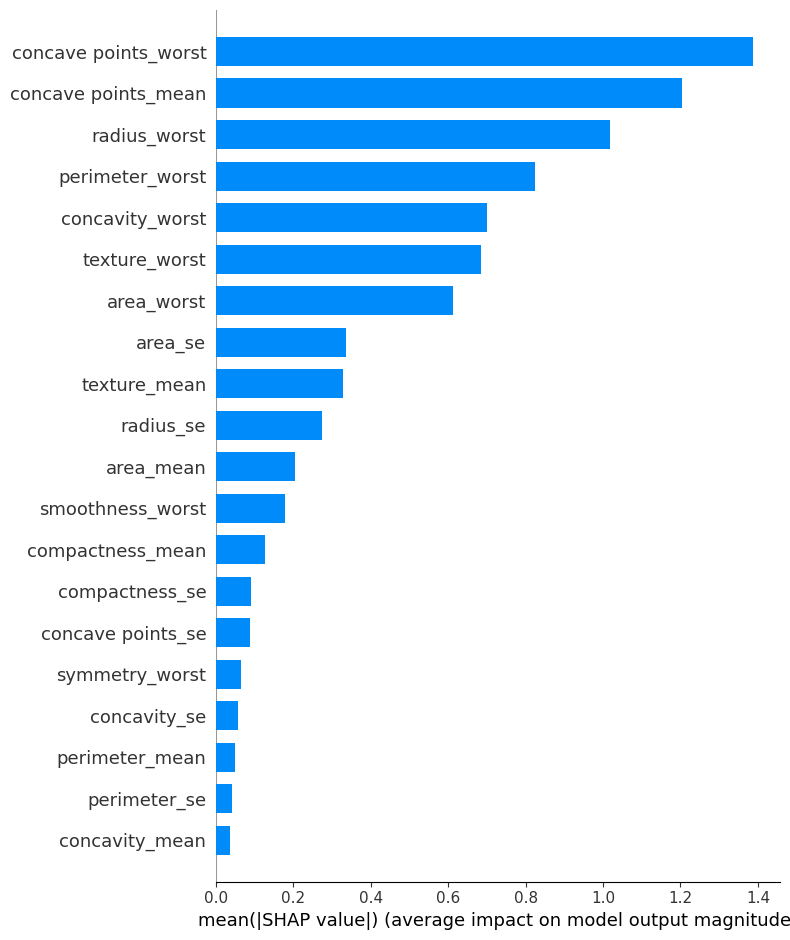

In [48]:
# CREATE SHAP EXPLAINER FOR GRADIENT BOOSTING
explainer = shap.TreeExplainer(gd_model)

# COMPUTE SHAP VALUES FOR THE TEST SET
shap_values = explainer.shap_values(X_test)

# TO SHOW WHICH FEATURES ARE MOST IMPORTANT OVERALL IN GRADIENT BOOSTING
shap.summary_plot(shap_values, X_test, plot_type="bar")


## Notes

- This is a transcription/reconstruction from the provided PDF, not the original notebook file.
- The PDF shows the original CSV path as `/content/Breast_cancer_dataset.csv`; upload that CSV to Colab or change the path as needed.
- Some lines were cut off in the PDF text rendering. Those lines have been completed where the intended code was clear, especially imports, train/test split, and metric-table construction.
- The PDF contains three trained models (SVM, Random Forest, Gradient Boosting), not the eight-model comparison mentioned in other project notes.